# Chapter 5 · Derivatives and the Jacobian

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 5 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 5)
deg = np.pi / 180
l1, l2 = 1.0, 1.0

def fk(q):
    # hand position of the planar 2-link arm
    return np.array([l1*np.cos(q[0]) + l2*np.cos(q[0]+q[1]), l1*np.sin(q[0]) + l2*np.sin(q[0]+q[1])])

def arm_pts(q):
    e = np.array([l1*np.cos(q[0]), l1*np.sin(q[0])])
    return np.array([[0, 0], e, fk(q)])

def draw_arm(ax, q, color="C0", alpha=1.0):
    ax.plot(*arm_pts(q).T, "o-", lw=4, ms=9, color=color, alpha=alpha)

def setup(ax, lim=2.4, title=""):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(title)

## 5.1 Derivatives and linear approximation
$f(a+\delta)\approx f(a)+f'(a)\,\delta$: near a point, a curve looks like its tangent line.

In [2]:
f, fp = np.sin, np.cos
a = 1.0
for delta in [0.5, 0.1, 0.01]:
    print(f"delta={delta:<5}  true f(a+delta)={f(a+delta):.6f}   linear estimate={f(a) + fp(a)*delta:.6f}")

delta=0.5    true f(a+delta)=0.997495   linear estimate=1.111622
delta=0.1    true f(a+delta)=0.891207   linear estimate=0.895501
delta=0.01   true f(a+delta)=0.846832   linear estimate=0.846874


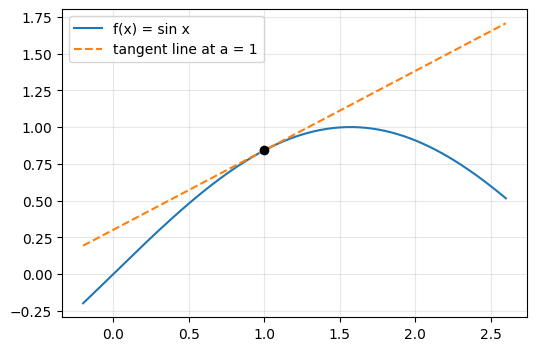

In [3]:
# the tangent line is the best straight-line stand-in for the curve near a = 1
fa, fpa = np.sin, np.cos; a = 1.0; xs = np.linspace(-0.2, 2.6, 200)
plt.figure(figsize=(6, 4)); plt.plot(xs, fa(xs), label="f(x) = sin x"); plt.plot(xs, fa(a) + fpa(a) * (xs - a), "--", label="tangent line at a = 1")
plt.plot(a, fa(a), "ko"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5.2 Partial derivatives
Wiggle one input at a time, holding the others fixed.

In [4]:
x, y = sp.symbols("x y")
f = x**2 * y + 3 * y**2
print("df/dx =", sp.diff(f, x), "   df/dy =", sp.diff(f, y))
print("at (2, 1):", sp.diff(f, x).subs({x: 2, y: 1}), sp.diff(f, y).subs({x: 2, y: 1}))

df/dx = 2*x*y    df/dy = x**2 + 6*y
at (2, 1): 4 10


## 5.3 and 5.4 The Jacobian, and the Jacobian of the two-link arm
$J_{ij}=\partial f_i/\partial q_j$, and the central equation is $\dot x=J(q)\,\dot q$ (hand velocity = Jacobian $\times$ joint velocities). Below: derive it symbolically, then check it against finite differences. **Column $i$ of $J$ is what the hand does when only joint $i$ turns.**

In [5]:
q1s, q2s = sp.symbols("q1 q2")
p = sp.Matrix([l1*sp.cos(q1s) + l2*sp.cos(q1s+q2s), l1*sp.sin(q1s) + l2*sp.sin(q1s+q2s)])
J_sym = p.jacobian([q1s, q2s])
print("Jacobian of the 2-link arm:"); sp.pprint(sp.simplify(J_sym))
jac = sp.lambdify((q1s, q2s), J_sym, "numpy")
J = lambda q: np.array(jac(*q), float)

# Check xdot = J qdot against finite differences of the forward kinematics
q = np.array([40*deg, 70*deg]); qdot = np.array([0.3, -0.5]); h = 1e-6
numeric = (fk(q + h*qdot) - fk(q - h*qdot)) / (2*h)
print("\nJ(q) @ qdot =", J(q) @ qdot, "\nfinite differences of FK =", numeric)

Jacobian of the 2-link arm:


⎡-1.0⋅sin(q₁) - 1.0⋅sin(q₁ + q₂)  -1.0⋅sin(q₁ + q₂)⎤
⎢                                                  ⎥
⎣1.0⋅cos(q₁) + 1.0⋅cos(q₁ + q₂)   1.0⋅cos(q₁ + q₂) ⎦

J(q) @ qdot = [-0.0049  0.2982] 
finite differences of FK = [-0.0049  0.2982]


In [6]:
q = np.array([40*deg, 70*deg])
joint_pos = [np.array([0, 0]), np.array([l1*np.cos(q[0]), l1*np.sin(q[0])])]
hand = fk(q)
cols = []
for jp in joint_pos:
    r = hand - jp                               # from the joint to the hand
    cols.append(np.array([-r[1], r[0]]))        # omega (= 1 rad/s about z) x r, in 2D
print("columns built from 'spin about each joint':\n", np.array(cols).T, "\nJacobian from calculus:\n", J(q))

columns built from 'spin about each joint':
 [[-1.5825 -0.9397]
 [ 0.424  -0.342 ]] 
Jacobian from calculus:
 [[-1.5825 -0.9397]
 [ 0.424  -0.342 ]]


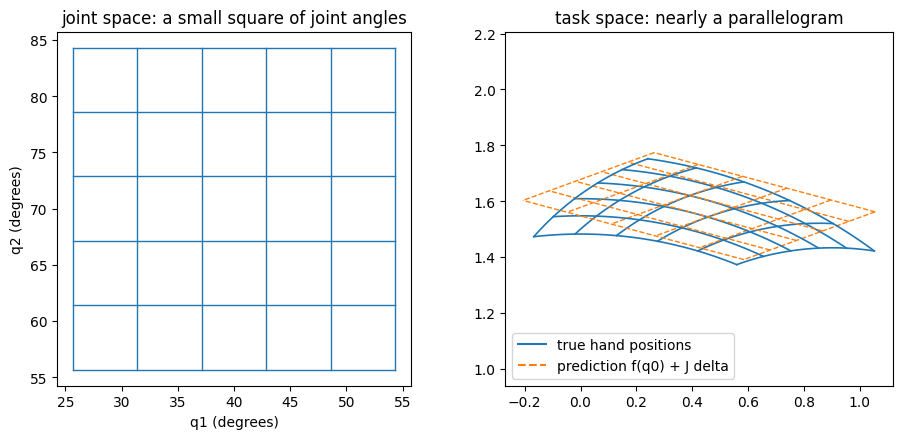

In [7]:
# the Jacobian as a local linear map: a small square of joint angles -> hand positions
q0 = np.array([40*deg, 70*deg]); grid = np.linspace(-.25, .25, 6); fine = np.linspace(-.25, .25, 40)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for u in grid:
    axes[0].plot(np.degrees(q0[0] + u) * np.ones_like(fine), np.degrees(q0[1] + fine), "C0", lw=1)
    axes[0].plot(np.degrees(q0[0] + fine), np.degrees(q0[1] + u) * np.ones_like(fine), "C0", lw=1)
    for first in (True, False):
        pts = np.array([fk(q0 + (np.array([u, v]) if first else np.array([v, u]))) for v in fine]); axes[1].plot(*pts.T, "C0", lw=1.2)
        lin = np.array([fk(q0) + J(q0) @ (np.array([u, v]) if first else np.array([v, u])) for v in fine]); axes[1].plot(*lin.T, "C1--", lw=1)
axes[0].set_xlabel("q1 (degrees)"); axes[0].set_ylabel("q2 (degrees)"); axes[0].set_title("joint space: a small square of joint angles"); axes[0].set_aspect("equal")
axes[1].plot([], [], "C0", label="true hand positions"); axes[1].plot([], [], "C1--", label="prediction f(q0) + J delta"); axes[1].legend(loc="lower left"); axes[1].set_aspect("equal", adjustable="datalim"); axes[1].set_title("task space: nearly a parallelogram")
plt.show()

## 5.5 Singularities
When $\det J=0$ the Jacobian squashes a direction flat: the hand cannot move that way. Send every unit joint speed through $J$ and you get an *ellipse* of hand velocities (the singular-value picture of Chapter 1); at a singularity it collapses to a line.

det J == l1 l2 sin(q2): True


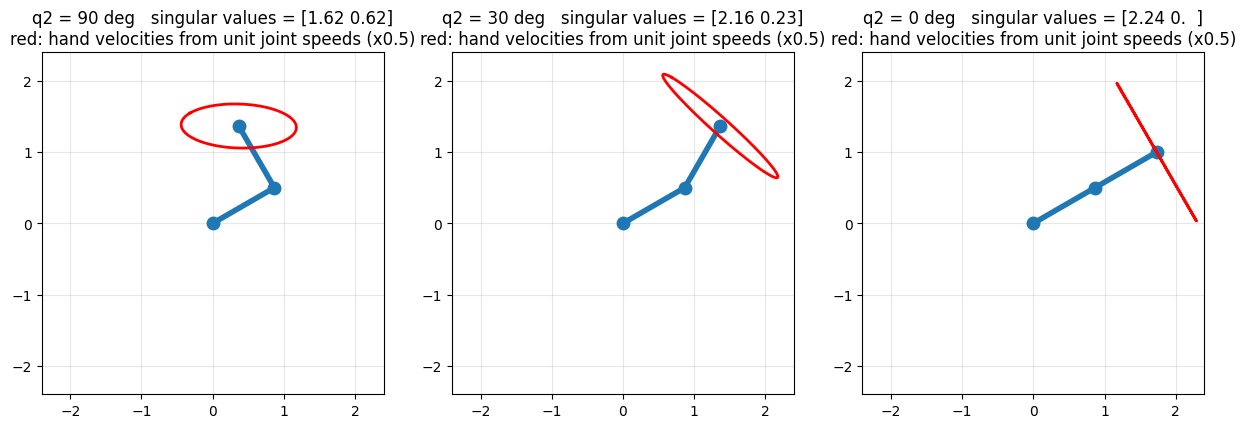

In [8]:
q2 = np.linspace(-np.pi, np.pi, 300)
dets = np.array([np.linalg.det(J([0.3, v])) for v in q2])
print("det J == l1 l2 sin(q2):", np.allclose(dets, l1*l2*np.sin(q2)))

t = np.linspace(0, 2*np.pi, 200); circle = np.vstack([np.cos(t), np.sin(t)])
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, q in zip(axes, [np.array([30*deg, 90*deg]), np.array([30*deg, 30*deg]), np.array([30*deg, 0*deg])]):
    draw_arm(ax, q); hand = fk(q); ell = J(q) @ circle
    ax.plot(hand[0] + 0.5*ell[0], hand[1] + 0.5*ell[1], "r", lw=2)
    s = np.linalg.svd(J(q), compute_uv=False)
    setup(ax, 2.4, f"q2 = {q[1]/deg:.0f} deg   singular values = {s.round(2)}\nred: hand velocities from unit joint speeds (x0.5)")
plt.show()

## 5.6 Statics: forces and torques
Power is frame-independent, so $\tau\cdot\dot q=F\cdot(J\dot q)$, which gives $\tau=J^\top F$. Velocities use $J$; forces use $J^\top$.

In [9]:
q = np.array([40*deg, 70*deg]); F = np.array([0, -10.0])      # hand supports a 10 N load pulling down
tau = J(q).T @ F
print("joint torques needed:", tau, "N m")

# power matches for any joint motion
qdot = np.array([0.4, -0.2])
print("power at joints tau.qdot =", tau @ qdot, "   power at hand F.xdot =", F @ (J(q) @ qdot))

joint torques needed: [-4.2402  3.4202] N m
power at joints tau.qdot = -2.3801374858245747    power at hand F.xdot = -2.3801374858245747


---
## Exercises

> **Exercise 5.1**
>
> Compute $\partial f/\partial x$ and $\partial f/\partial y$ for $f(x,y)=3x^2-xy+y^3$ and evaluate them at $(1,2)$.

In [10]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 5.1** *(this is the book's Appendix B, checked in code)*

In [11]:
fx = 3*x**2 - x*y + y**3
dx_, dy_ = sp.diff(fx, x), sp.diff(fx, y); print(dx_, "|", dy_, "|", dx_.subs({x: 1, y: 2}), dy_.subs({x: 1, y: 2}))
assert dx_.subs({x: 1, y: 2}) == 4 and dy_.subs({x: 1, y: 2}) == 11

6*x - y | -x + 3*y**2 | 4 11


> **Exercise 5.2**
>
> Find the Jacobian of $f(x,y)=(xy,\ x+y^2)$ and evaluate it at $(2,1)$.

In [12]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 5.2** *(this is the book's Appendix B, checked in code)*

In [13]:
g = sp.Matrix([x*y, x + y**2]); Jg = g.jacobian([x, y]); print(Jg, Jg.subs({x: 2, y: 1})); assert Jg.subs({x: 2, y: 1}) == sp.Matrix([[1, 2], [1, 2]])

Matrix([[y, x], [1, 2*y]]) Matrix([[1, 2], [1, 2]])


> **Exercise 5.3**
>
> Write the Jacobian of the two-link arm ($l_1=l_2=1$) at $q=(0,0)$. In which direction can the hand not move?

In [14]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 5.3** *(this is the book's Appendix B, checked in code)*

In [15]:
print(J([0, 0])); assert np.allclose(J([0, 0]), [[0, 0], [2, 1]])
print("first row is zero: the hand cannot move along x")

[[-0. -0.]
 [ 2.  1.]]
first row is zero: the hand cannot move along x


> **Exercise 5.4**
>
> At $q=(0,0)$ the hand supports $F=(0,-5)$. Find $\tau=J^\top F$.

In [16]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 5.4** *(this is the book's Appendix B, checked in code)*

In [17]:
tau = J([0, 0]).T @ np.array([0, -5.0]); print(tau); assert np.allclose(tau, [-10, -5])
print("hand at (2,0): base torque 2*(-5) = -10; the elbow is 1 away: -5")

[-10.  -5.]
hand at (2,0): base torque 2*(-5) = -10; the elbow is 1 away: -5


---
**Next:** `06_Inverse_Kinematics_and_Trajectories.ipynb` (Chapter 6)

*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com